# Class 19: Hypothesis tests continued

Plan for today. Each numbered section below follows a part of the slides, so when you reach the next section, go back to the slides.

1. Warm-up: our coin-flip experiment
2. Hypothesis tests for causal relationships (from class 18)
3. Hypothesis tests for two means: smoking and baby weights
4. Hypothesis tests for correlation
5. Visual hypothesis tests
6. Two-sided hypothesis tests

In [ ]:
import YData

# YData.download.download_class_code(19)   # get class code    
# YData.download.download_class_code(19, True) # get the code with the answers 

# YData.download.download_class_file('project_template.ipynb', 'homework')  # downloads the class project template 
# YData.download_homework(8)  # downloads the 8th homework 

YData.download_data("bta.csv")
YData.download_data("babies.csv")
YData.download_data("amazon.csv")

The file `bta.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.


'amazon.csv'

In [ ]:
import pandas as pd
import numpy as np
np.random.seed(123)   # fixed seed so results are reproducible
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


## 1. Warm-up: our coin-flip experiment


Recall our in-class experiment of predicting coin flips. Let's do our hypothesis test.

We are not deciding on medicine, just if someone here has magical powers, so let's take p = 0.07 as our cutoff.



#### Step 1: State the null and alternative hypotheses

Null hypothesis: the student is guessing, so each coin flip matches the prediction with probability one half:

$H_0: \pi = 0.5$

Alternative hypothesis: the student predicts better than guessing:

$H_A: \pi > 0.5$

#### Step 2: Calculate the observed statistic of interest

All $4$ coin flips matched the prediction:

$\hat{p} = 1$


In [ ]:
prop = 4/4

#### Step 3: Create the null distribution 

We need to create a null distribution, which is the distribution of statistics we would expect to get if the null hypothesis is true. 

**Question**: about what percent of the coin tosses would we expect to match the prediction if the null hypothesis were true? 

**Answer**: 50%

Let's create simulated data that is consistent with this!

**There are a few models we can build for our experiment, they are mostly equivalent if we assume a fair coin, but this can be a little subtle.** 

In [ ]:
# function we had before
# Add an argument return_prop that when set to True will return the proportion of coin flips that were heads (rather than the number of heads)

def flip_coins(n, prob, return_prop = False):
    
    rand_nums = np.random.rand(n)
    num_heads = np.sum(rand_nums <= prob)
    
    if return_prop:
        return num_heads/n
    else:
        return num_heads
    
    
print(flip_coins(4, .5))
print(flip_coins(4, .5, True))

2
0.25


In [ ]:
# Let's write a version for this experiment

def match_flip_coins(myflips):
    
    rand_nums = np.random.rand(len(myflips))
    is_head = rand_nums <= 0.5
    
    is_match = (is_head == myflips)
    num_match = is_match.sum()

    return num_match/len(myflips)


print(match_flip_coins(np.array([1, 0, 1, 0])))

# This turns out to be equivalent to the previous code (under some assumptions). Try to compare the distributions and think why this is the case?


0.75


In [ ]:
# Let's generate a null distribution 

null_dist = []

for i in range(10000):
    simulated_guess = (np.random.rand(4) <= 0.5)
    simulated_null_prop = match_flip_coins(simulated_guess)
    null_dist.append(simulated_null_prop)

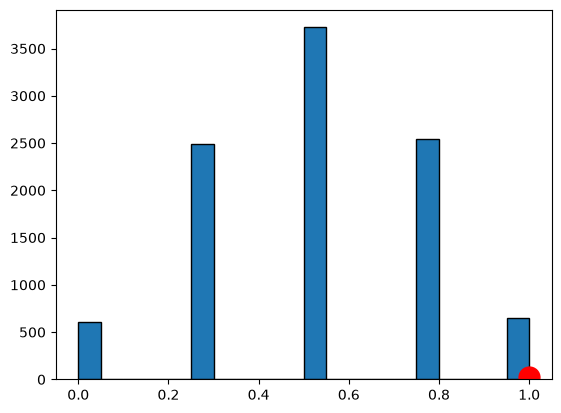

In [ ]:
# visualize the null distribution 

plt.hist(null_dist, edgecolor = "black", bins = 20) #, range = (.4, .6));
plt.plot(prop, 30, '.', markersize = 30, color = "red");

#### Step 4: Calculate the p-value 

Calculate the proportion of points in the null distribution that are more extreme than the observed statistic. 


In [ ]:
# Calculate the p-value

# create a Boolean vector indicating whether each p-hat in the null distribution 
# was greater than or equal to the observed proportion 
stats_more_extreme = np.array(null_dist) >= prop

print(stats_more_extreme[0:5])

# calculate the p-value 
p_value = np.mean(stats_more_extreme)

p_value


[False False False False False]


np.float64(0.0648)

#### Step 5: Make a decision

Since the p-value is below our cutoff of 0.07, it is fairly unlikely that our statistic came from the null distribution. Thus we will reject the null hypothesis and conclude that we have a person with magical power in class!


***Or do we?***


## 2. Hypothesis test assessing causal relationships

To get at causality we can run a Randomized Controlled Trial (RCT), where half of the participants are randomly assigned to a "treatment group" that receives an intervention and the other half of participants are put in a "control group" which receives a placebo. If the treatment group shows an improvement over the control group that is larger than what is expected by chance, this indicates that the treatment **causes** an improvement. 


#### Botulinum Toxin A (BTA) as a treatment to chronic back pain

A study by Foster et al (2001) examined whether Botulinum Toxin A (BTA) was an effective treatment for chronic back pain.

In the study, participants were randomly assigned to be in a treatment or control group: 
- 15 in the treatment group
- 16 in the control group (normal saline)

Trials were run double-blind (neither doctors nor patients knew which group they were in)

Results from the study were coded as:
  - 1 indicates pain relief
  - 0 indicates lack of pain relief 


Let's run a hypothesis test to see if BTA causes a decrease in back pain.

### Step 1: State the null and alternative hypotheses


$H_0$: $\pi_{treat} =  \pi_{control}$   or    $H_0$: $\pi_{treat} -  \pi_{control} = 0$ 

$H_A$: $\pi_{control} < \pi_{treat}$    or    $H_A$: $\pi_{treat} -  \pi_{control} > 0$ 



Where $\pi_{treat}$ and $\pi_{control}$ are the population proportions of people who experienced back pain relief after receiving the BTA or control respectively. 


### Step 2: Calculate the observed statistic

The code below loads the data from the study. We can use the difference in proportions  $\hat{p}_{treat} - \hat{p}_{control}$  as our observed statistic. 

Let's calculate the observed statistic and save it to the name `obs_stat`.


In [ ]:
bta = pd.read_csv('bta.csv')
bta.sample(frac = 1)

,Group,Result
29,Treatment,0.0
4,Control,0.0
20,Treatment,1.0
2,Control,0.0
30,Treatment,0.0
18,Treatment,1.0
11,Control,0.0
1,Control,1.0
21,Treatment,1.0
17,Treatment,1.0


In [ ]:
# create a DataFrame with the proportion of people in the treatment and control groups that have pain relief 

results_table = bta.groupby("Group").mean()

results_table

,Result
Group,
Control,0.125
Treatment,0.600


In [ ]:
# calculate the difference
obs_stat_series = results_table.loc["Treatment"] - results_table.loc["Control"]

# extract the number from the Series
obs_stat = obs_stat_series.iloc[0]

obs_stat


np.float64(0.475)

In [ ]:
# let's write a function to make it easy to get statistic values

def get_prop_diff(bta_data):
    
    group_means = bta_data.groupby("Group").mean()
    
    the_difference = group_means.loc["Treatment"] - group_means.loc["Control"]
    
    return the_difference.iloc[0]


# Try the function out
get_prop_diff(bta)


np.float64(0.475)

### Step 3: Create the null distribution 

To create the null distribution, we need to create statistics consistent with the null hypothesis. 

In this example, if the null hypothesis was true, then there would be no difference between the treatment and control group. Thus, under the null hypothesis, we can shuffle the group labels and get equally valid statistics. 

Let's create one statistic consistent with the null distribution to understand the process. We can then repeat this 10,000 times to get a full null distribution. 

In [ ]:
# shuffle the data 

shuff_bta = bta.copy()
shuff_bta['Group'] = np.random.permutation(bta["Group"])

shuff_bta.head()

,Group,Result
0,Control,1.0
1,Treatment,1.0
2,Control,0.0
3,Control,0.0
4,Treatment,0.0


In [ ]:
# get one statistic consistent with the null distribution 

get_prop_diff(shuff_bta)

np.float64(0.08750000000000002)

In [ ]:
%%time

# create a full null distribution 

null_dist = []

for i in range(10000):
    
    shuff_bta['Group'] = np.random.permutation(bta["Group"])
    
    shuff_stat = get_prop_diff(shuff_bta)
    
    null_dist.append(shuff_stat)

CPU times: user 7.96 s, sys: 250 ms, total: 8.21 s
Wall time: 10.9 s


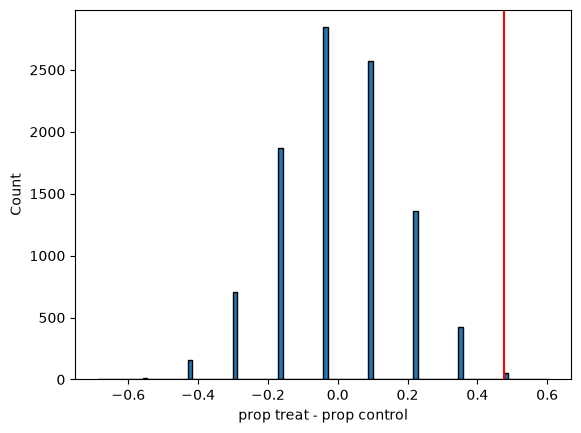

In [ ]:
# visualize the null distribution 

plt.hist(null_dist, edgecolor = "black", bins = 100);


# put a line at the observed statistic value

plt.axvline(obs_stat, color = "red");
plt.xlabel("prop treat - prop control");
plt.ylabel("Count");

### Step 4: Calculate the p-value

The p-value is the proportion of points in the null distribution that are more extreme than the observed statistic. 


In [ ]:
p_value = np.mean(np.array(null_dist) >= obs_stat)

p_value

np.float64(0.0056)

### Step 5: Draw a conclusion

Since the p-value is less than the typical significance level of 0.05, we can reject the null hypothesis. Because the participants were **randomly assigned to the treatment and control groups**, we can conclude that BTA does **cause** pain relief at a higher rate than the placebo. 

<br>
<center>
<img src="https://image.spreadshirtmedia.com/image-server/v1/compositions/T347A2PA4306PT17X24Y42D1035176833W20392H24471/views/1,width=550,height=550,appearanceId=2,backgroundColor=000000,noPt=true/ok-but-first-botox-fillers-botox-funny-botox-womens-t-shirt.jpg" alt="botox" style="width: 200px;"/>
</center>
<br>

## 3. Hypothesis test for two means: smoking and baby weights

The Child Health and Development Studies investigate a range of topics. One study, in particular, considered all pregnancies between 1960 and 1967 among women in the Kaiser Foundation Health Plan in the San Francisco East Bay area.

Let's examine these data to see whether babies of mothers who do not smoke weigh more, on average, than babies of mothers who smoke. 


### Step 1: State the null and alternative hypotheses


$H_0$: $\mu_{non-smoke} =  \mu_{smoke}$   or    $H_0$: $\mu_{non-smoke} -  \mu_{smoke} = 0$ 

$H_A$: $\mu_{non-smoke} >  \mu_{smoke}$   or    $H_A$: $\mu_{non-smoke} -  \mu_{smoke} > 0$ 


Where $\mu_{non-smoke}$ and $\mu_{smoke}$ are the population mean weights of babies born to mothers who did not smoke and who smoked.

### Step 2: Calculate the observed statistic

The code below loads the data from the study. The two relevant columns are:
- `bwt`: The birth weight of the baby in ounces
- `smoke`: whether the mother smokes (1) or does not smoke (0)

More information about the data is available at: https://www.openintro.org/data/index.php?data=babies

In [ ]:
babies = pd.read_csv("babies.csv")

babies.head()

,case,bwt,gestation,parity,age,height,weight,smoke
0,1,120,284.0,0,27.0,62.0,100.0,0.0
1,2,113,282.0,0,33.0,64.0,135.0,0.0
2,3,128,279.0,0,28.0,64.0,115.0,1.0
3,4,123,NaN,0,36.0,69.0,190.0,0.0
4,5,108,282.0,0,23.0,67.0,125.0,1.0


To simplify the analysis, create a new DataFrame called `babies2` that only has the smoke and bwt columns. 

In [ ]:
# create a DataFrame called babies2 that has only the smoke and bwt columns
babies2 = babies[["smoke", "bwt"]]
babies2.head(3)

,smoke,bwt
0,0.0,120
1,0.0,113
2,1.0,128


Let's have our observed statistic be the difference of sample means  $\bar{x}_{non-smoke} - \bar{x}_{smoke}$.  

Please calculate this observed statistic and save it to the name `obs_stat`.


In [ ]:
results_table = babies2.groupby("smoke").mean()
results_table

,bwt
smoke,
0.0,123.047170
1.0,114.109504


In [ ]:

obs_stat_series = results_table.iloc[0] - results_table.iloc[1]

obs_stat = obs_stat_series.iloc[0]

obs_stat


np.float64(8.93766567908935)

To make the rest of the analysis easier, write a function `get_diff_baby_weights(babies_df)` that will take a DataFrame `babies_df` that has the `smoke` and `bwt` columns, and returns the mean weight of babies whose mothers do not smoke minus the mean weight of babies whose mothers smoke. 

Also, test the function to make sure it gives the same observed statistic you calculated above

In [ ]:
def get_diff_baby_weights(babies_df):
    
    results_table = babies_df.groupby("smoke").mean()
    obs_stat_series = results_table.iloc[0] - results_table.iloc[1]
    return obs_stat_series.iloc[0]


# get that the function works

get_diff_baby_weights(babies2)


np.float64(8.93766567908935)

### Step 3: Create the null distribution 

Now let's create a null distribution that has 10,000 statistics that are consistent with the null hypothesis. 

In this example, if the null hypothesis was true, then there would be no difference between the smoking mothers and the non-smoking mothers. Thus, under the null hypothesis, we can shuffle the group labels and get equally valid statistics. 

Let's create one statistic consistent with the null distribution to understand the process. We can then repeat this 10,000 times to get a full null distribution. 

In [ ]:
# shuffle the data 

shuff_babies = babies2.copy()
shuff_babies['smoke'] = np.random.permutation(shuff_babies["smoke"])

get_diff_baby_weights(shuff_babies)


np.float64(-0.2955603573099239)

In [ ]:
%%time

# create a full null distribution 

null_dist = []

for i in range(10000):  
    
    shuff_babies['smoke'] = np.random.permutation(shuff_babies["smoke"])
    
    shuff_stat = get_diff_baby_weights(shuff_babies)
    
    null_dist.append(shuff_stat)

CPU times: user 5.29 s, sys: 89.4 ms, total: 5.38 s
Wall time: 6.41 s


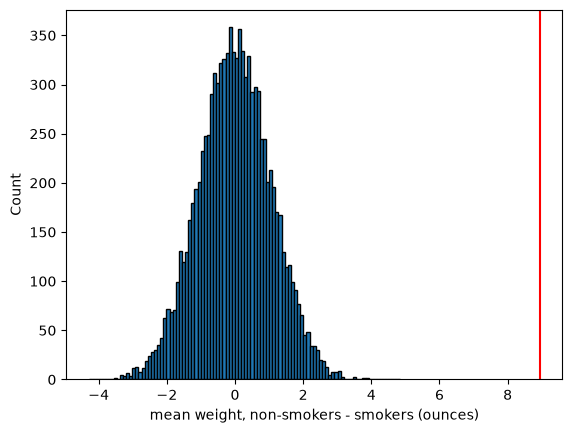

In [ ]:
# visualize the null distribution 

plt.hist(null_dist, edgecolor = "black", bins = 100);


# put a line at the observed statistic value

plt.axvline(obs_stat, color = "red");
plt.xlabel("mean weight, non-smokers - smokers (ounces)");
plt.ylabel("Count");

### Step 4: Calculate the p-value

The p-value is the proportion of points in the null distribution that are more extreme than the observed statistic. 


In [ ]:
p_value = np.mean(np.array(null_dist) >= obs_stat)

p_value


np.float64(0.0)

### Step 5: Draw a conclusion

Since the p-value is less than the typical significance level of 0.05, we can reject the null hypothesis. We conclude that babies born to mothers who do not smoke weigh more, on average, than babies born to mothers who smoke. 

However, because this was an observational study, where mothers were **not** randomly assigned to smoke or not to smoke, we **cannot** conclude that smoking causes babies to weigh less when they are born. In particular, there could be other "lurking/confounding" variables that are associated both with whether the mothers smoke and with how much the babies weigh. 

<br>
<center>
<img src="https://i.ytimg.com/vi/x4c_wI6kQyE/maxresdefault.jpg" alt="smoking" style="width: 300px;"/>
</center>
<br>

## 4. Hypothesis tests for correlation

Let's run a hypothesis test for correlation to see if books that have more pages cost more! 


### Step 1: State the null and alternative hypotheses

**In words** 

Null hypothesis: There is no correlation between the number of pages in a book and the cost of the book. 

Alternative hypothesis: Books that have more pages cost more. 

**In symbols**

$H_0$: $\rho = 0$  

$H_A$: $\rho > 0$  


### Step 2: Calculate the observed statistic

Data on 230 books from Amazon.com are loaded below. Let's calculate the observed correlation ($r$) between the number of pages in the book (`NumPages`) and the listed price (`List.Price`). 

To make your life easier, first just reduce the data set to only the `NumPages` and `List.Price` columns and save this to a DataFrame called `amazon_smaller`. Then use `amazon_smaller` for the rest of this problem


In [ ]:
amazon = pd.read_csv("amazon.csv")

amazon.head(3)

,Title,Author,List.Price,Amazon.Price,Hard..Paper,NumPages,Publisher,Pub.year,ISBN.10,Height,Width,Thick,Weight..oz.
0,"1,001 Facts that Will Scare the S#*t Out of Yo...",Cary McNeal,12.95,5.18,P,304,Adams Media,2010.0,1605506249,7.8,5.5,0.8,11.2
1,21: Bringing Down the House - Movie Tie-In: Th...,Ben Mezrich,15.00,10.20,P,273,Free Press,2008.0,1416564195,8.4,5.5,0.7,7.2
2,100 Best-Loved Poems (Dover Thrift Editions),Smith,1.50,1.50,P,96,Dover Publications,1995.0,486285537,8.3,5.2,0.3,4.0


In [ ]:
import statistics

amazon_smaller = amazon[["NumPages", "List.Price"]]

obs_stat = statistics.correlation(amazon_smaller.NumPages, amazon_smaller["List.Price"])

obs_stat


0.21455197256312525

### Step 3: Create the null distribution 

How can we create one statistic consistent with the null hypothesis? 

See if you can create one statistic consistent with the null distribution below. Once you have done that, create the full null distribution!



In [ ]:
# Create one statistic consistent with the null distribution
statistics.correlation(amazon_smaller.NumPages, np.random.permutation(amazon_smaller["List.Price"]))

np.float64(-0.03070094724375882)

In [ ]:
%%time

# Create the full null distribution

null_dist = []

for i in range(10000):  
        
    shuff_stat = statistics.correlation(amazon_smaller.NumPages, 
                                        np.random.permutation(amazon_smaller["List.Price"]))
    
    null_dist.append(shuff_stat)



CPU times: user 1.52 s, sys: 30.4 ms, total: 1.55 s
Wall time: 1.94 s


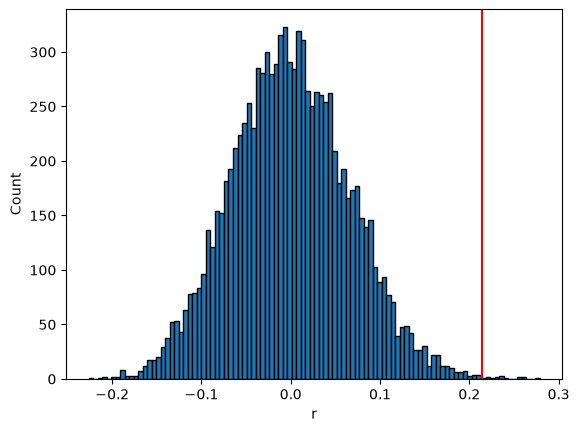

In [ ]:
# visualize the null distribution 

plt.hist(null_dist, edgecolor = "black", bins = 100);


# put a line at the observed statistic value

plt.axvline(obs_stat, color = "red");
plt.xlabel("r");
plt.ylabel("Count");

### Step 4: Calculate the p-value


In [ ]:
p_value = np.mean(np.array(null_dist) >= obs_stat)

p_value


np.float64(0.0015)

### Step 5: Draw a conclusion

The p-value is small (less than the conventional level of 0.05), so we would reject the null hypothesis and conclude that there is a positive correlation between the number of pages in a book and the price of a book at the population level. 


## 5. Visualizing hypothesis tests for correlation

We can also run a visual hypothesis test for correlation by creating a visual lineup that displays several scatter plots of shuffled data and one scatter plot of the real data. If you can tell which plot contains the real (unshuffled) data, this corresponds to being able to reject the null hypothesis. 


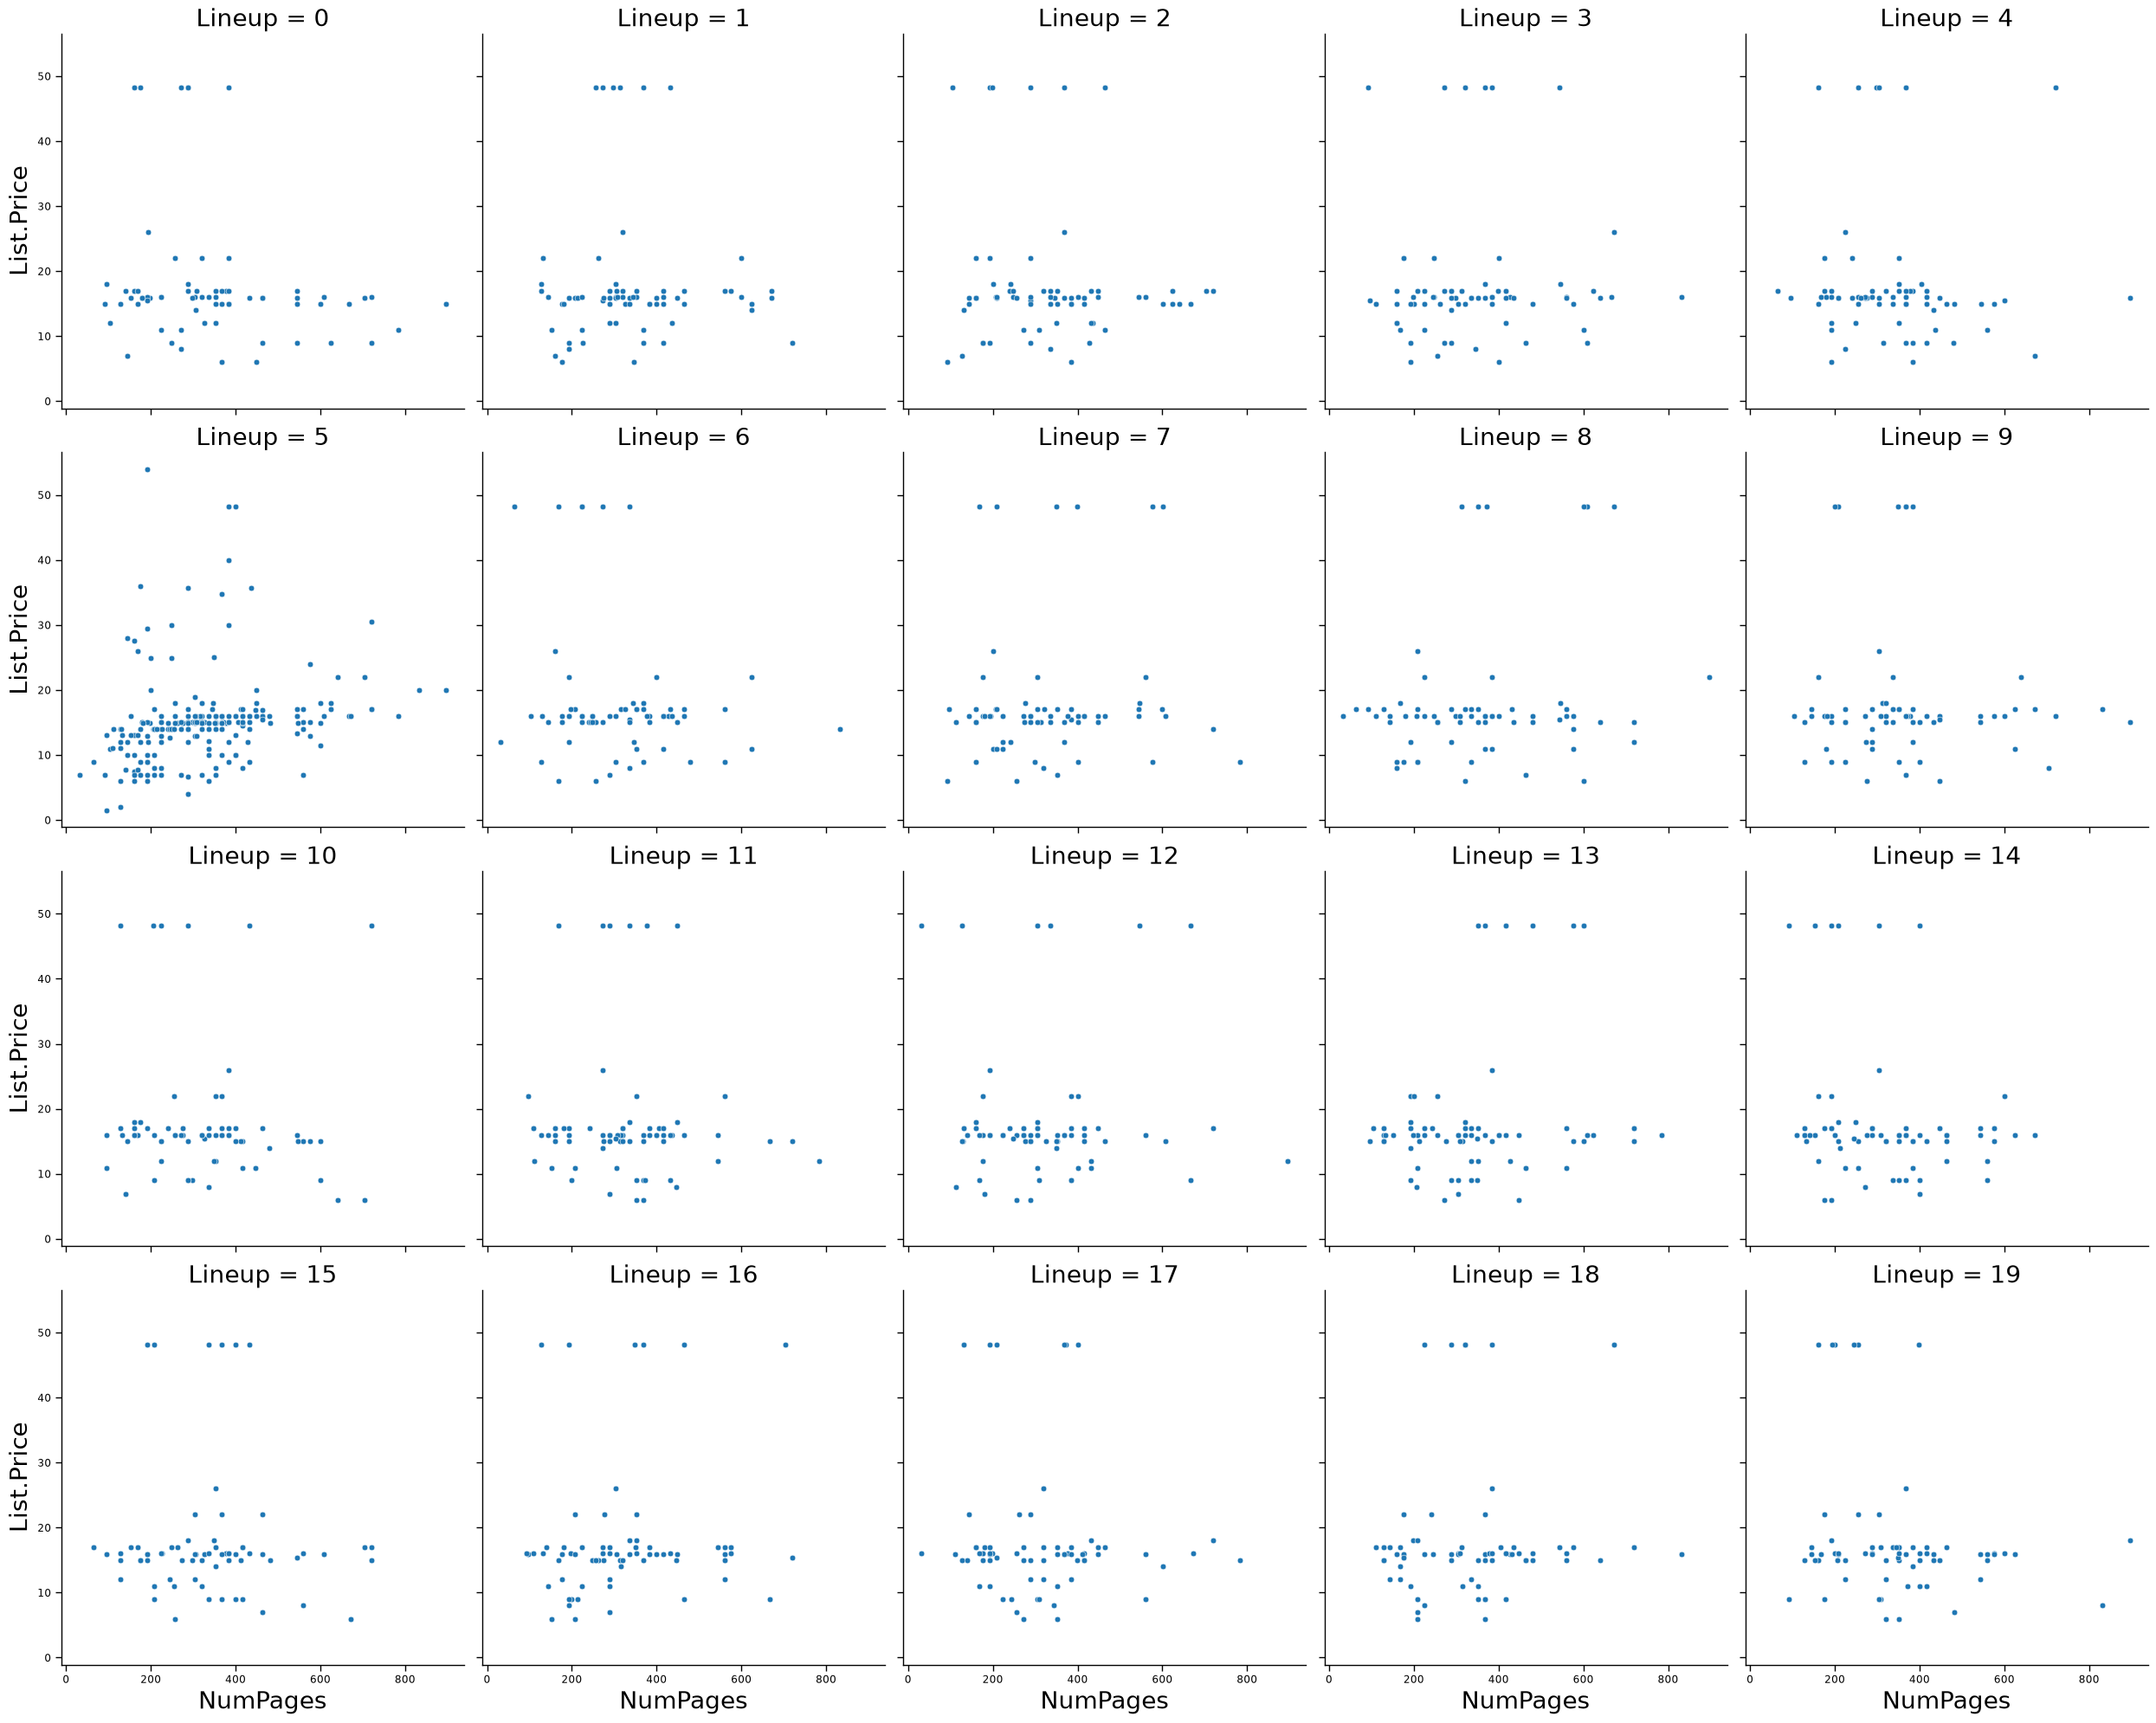

In [ ]:
def create_lineup(the_data): 
    
    real_plot_num = np.random.permutation(range(20))[0]
    lineup_data = pd.DataFrame()
    
    for i in range(20):
        
        if i == real_plot_num:
            curr_data = the_data.copy()
        
        else:
            curr_data = pd.DataFrame(the_data.iloc[:, 1], the_data.iloc[:, 0]).reset_index()
            curr_data[curr_data.columns[1]] = np.random.permutation(curr_data[curr_data.columns[1]])
        
        curr_data.loc[:, "Lineup"] = i
        lineup_data = pd.concat([lineup_data, curr_data])
        
    lineup_data = lineup_data.reset_index()

    sns.set_context("paper", rc={"axes.labelsize":20})   
    sns.relplot(lineup_data, x = lineup_data.columns[1], y = lineup_data.columns[2], col = "Lineup", col_wrap=5); 

    return real_plot_num


the_answer = create_lineup(amazon_smaller)



In [ ]:
# display the answer
print(the_answer)
# the_answer


5


## 6. Two-sided hypothesis test

Sometimes in hypothesis testing we don't know the direction of an effect; we only know that the null hypothesis is incorrect.

In these circumstances, we write our alternative hypothesis such that we state that the parameter value is not equal to the value specified by the null hypothesis.

For testing whether there is a correlation between the number of pages in a book and its price, we can write our hypotheses as:

$H_0: \rho = 0$

i.e., the null hypothesis is the same as before.

$H_A: \rho \ne 0$

We now use not equal to ($\ne$) in our alternative hypothesis.

To calculate the p-value, we need to look at the values more extreme than the observed statistic in both tails.

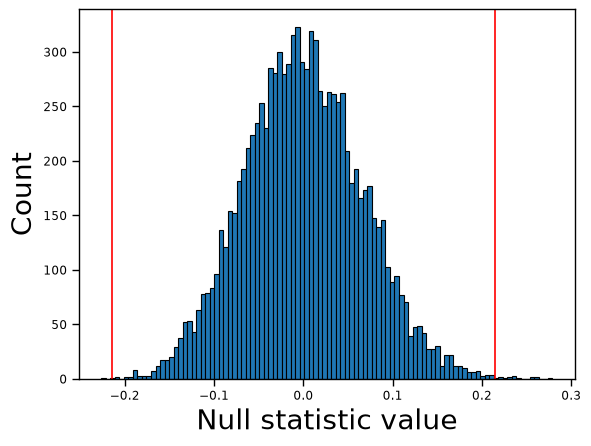

In [ ]:
# visualize the null distribution 

plt.hist(null_dist, edgecolor = "black", bins = 100);


# put lines showing values more extreme than the observed statistic

plt.axvline(obs_stat, color = "red");
plt.axvline(-1 * obs_stat, color = "red");

plt.xlabel("Null statistic value");
plt.ylabel("Count");


When calculating the p-value, we need to get the proportion of statistics in the null distribution that are more extreme than the observed statistic from both tails.

In [ ]:
p_value_right = np.mean(np.array(null_dist) >= obs_stat)
p_value_left = np.mean(np.array(null_dist) <= -1 * obs_stat)

p_value = p_value_right + p_value_left

p_value 


np.float64(0.0017000000000000001)